# 01 — Carga e exploração do Favorita

Etapa 1 da Fase 1 (`docs/PLANO_ML.md`). Objetivos:

1. conferir a tabela de fatos do plano contra os dados brutos;
2. enxergar tendência, sazonalidade (semanal e anual) e eventos anômalos;
3. entender o que significa "zero", "ausente" e "série" neste painel.

Os dados brutos (`data/raw/favorita/`) são **somente leitura**. Toda lógica reutilizável vive em `src/pipeline/`; aqui só se chama e se interpreta.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from pipeline.data import load_holidays, load_stores, load_train

plt.rcParams.update({
    "figure.figsize": (11, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.options.display.float_format = "{:,.2f}".format

daily = load_train()
stores = load_stores()
holidays = load_holidays()
daily.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.00,0
1,1,2013-01-01,1,BABY CARE,0.00,0
2,2,2013-01-01,1,BEAUTY,0.00,0
3,3,2013-01-01,1,BEVERAGES,0.00,0
4,4,2013-01-01,1,BOOKS,0.00,0


## 1. Painel em formato longo

Cada linha é **data × loja × família**. Uma *série* é um par (loja, família): 54 lojas × 33 famílias = 1.782 séries.
`sales` é o total de unidades da família na loja naquele dia (fracionário quando o item é vendido por peso);
`onpromotion` é a quantidade de itens da família em promoção.

In [2]:
dates_all = pd.date_range(daily.date.min(), daily.date.max())
missing_dates = dates_all.difference(daily.date.unique())
series_sizes = daily.groupby(["store_nbr", "family"], observed=True).size()

daily["week_start"] = daily.date - pd.to_timedelta(daily.date.dt.weekday, unit="D")  # segunda-feira
complete = daily[(daily.week_start >= "2013-01-07") & (daily.week_start <= "2017-08-07")]
weekly_by_series = complete.groupby(["store_nbr", "family", "week_start"], observed=True).sales.sum()
zero_weeks = (weekly_by_series == 0).groupby(["store_nbr", "family"], observed=True).sum()
first_positive = daily[daily.sales > 0].groupby("store_nbr").date.min()
late_stores = sorted(first_positive[first_positive > "2013-01-31"].index.tolist())


def br(n):
    return f"{n:,}".replace(",", ".")


facts = pd.DataFrame(
    [
        ("Linhas", "3.000.888", br(len(daily))),
        ("Colunas", "id, date, store_nbr, family, sales, onpromotion", ", ".join(daily.columns[:6])),
        ("Primeira data", "2013-01-01 (terça)", f"{daily.date.min():%Y-%m-%d} ({daily.date.min():%A})"),
        ("Última data", "2017-08-15 (terça)", f"{daily.date.max():%Y-%m-%d} ({daily.date.max():%A})"),
        ("Lojas × famílias", "54 × 33 = 1.782",
         f"{daily.store_nbr.nunique()} × {daily.family.nunique()} = {br(len(series_sizes))}"),
        ("Linhas por série", "1.684", ", ".join(map(str, series_sizes.unique()))),
        ("Datas ausentes", "só 25/12 de 2013 a 2016", ", ".join(d.strftime("%d/%m/%Y") for d in missing_dates)),
        ("Vendas zeradas", "31,3%", f"{(daily.sales == 0).mean():.1%}"),
        ("Vendas negativas", "nenhuma", str((daily.sales < 0).sum())),
        ("Vendas fracionárias", "15,4%", f"{(daily.sales % 1 != 0).mean():.1%}"),
        ("Semanas completas (seg–dom)", "240, de 2013-01-07 a 2017-08-13",
         f"{complete.week_start.nunique()}, de {complete.date.min():%Y-%m-%d} a {complete.date.max():%Y-%m-%d}"),
        ("Séries sem nenhuma semana zerada", "711 de 1.782", f"{(zero_weeks == 0).sum()} de {br(len(zero_weeks))}"),
        ("Lojas que abrem depois de jan/2013", "20, 21, 22, 29, 36, 42, 52, 53", ", ".join(map(str, late_stores))),
    ],
    columns=["Fato", "Esperado (PLANO_ML)", "Medido"],
)
facts.style.hide(axis="index")

Fato,Esperado (PLANO_ML),Medido
Linhas,3.000.888,3.000.888
Colunas,"id, date, store_nbr, family, sales, onpromotion","id, date, store_nbr, family, sales, onpromotion"
Primeira data,2013-01-01 (terça),2013-01-01 (Tuesday)
Última data,2017-08-15 (terça),2017-08-15 (Tuesday)
Lojas × famílias,54 × 33 = 1.782,54 × 33 = 1.782
Linhas por série,1.684,1684
Datas ausentes,só 25/12 de 2013 a 2016,"25/12/2013, 25/12/2014, 25/12/2015, 25/12/2016"
Vendas zeradas,"31,3%",31.3%
Vendas negativas,nenhuma,0
Vendas fracionárias,"15,4%",15.4%


In [3]:
assert len(daily) == 3_000_888
assert daily.date.min() == pd.Timestamp("2013-01-01") and daily.date.max() == pd.Timestamp("2017-08-15")
assert daily.store_nbr.nunique() == 54 and daily.family.nunique() == 33 and len(series_sizes) == 1782
assert set(series_sizes.unique()) == {1684}
assert [d.strftime("%m-%d") for d in missing_dates] == ["12-25"] * 4
assert [d.year for d in missing_dates] == [2013, 2014, 2015, 2016]
assert round((daily.sales == 0).mean() * 100, 1) == 31.3
assert (daily.sales < 0).sum() == 0
assert round((daily.sales % 1 != 0).mean() * 100, 1) == 15.4
assert complete.week_start.nunique() == 240
assert (zero_weeks == 0).sum() == 711
assert late_stores == [20, 21, 22, 29, 36, 42, 52, 53]
print("Tabela de fatos do plano reproduzida.")

Tabela de fatos do plano reproduzida.


### Ausente não é zero

O dia 25/12 **não tem linha** em nenhum ano (lojas fechadas). Já os 31,3% de zeros **têm linha** e podem significar três coisas diferentes:
*não vendeu naquele dia*, *a loja ainda não existia* ou *a família ainda não era registrada*. Os dois últimos são "zeros de cadastro", não de demanda.
Veja a seção 6, abaixo.

## 2. Venda total no tempo

Soma de todas as lojas e famílias. A linha grossa é a média móvel de 28 dias.

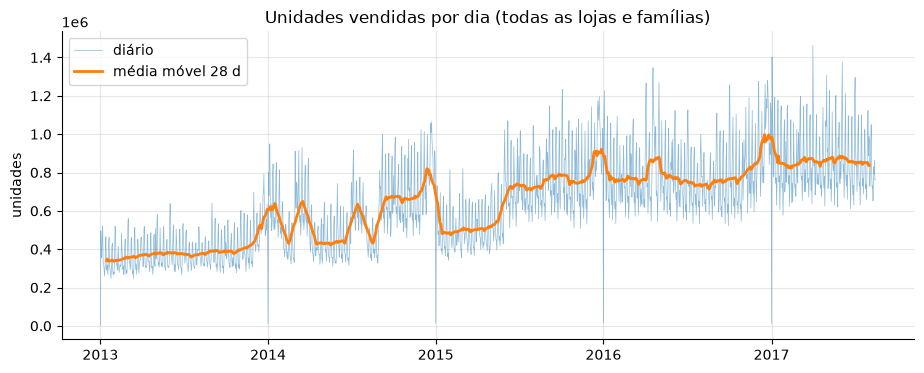

,unidades,dias,média diária
date,,,
2013,"140,419,013.92",364,"385,766.52"
2014,"209,474,246.30",364,"575,478.70"
2015,"240,880,100.65",364,"661,758.52"
2016,"288,654,522.95",365,"790,834.31"
2017,"194,217,068.37",227,"855,581.80"


In [4]:
total_daily = daily.groupby("date").sales.sum()

fig, ax = plt.subplots()
ax.plot(total_daily.index, total_daily, lw=0.5, alpha=0.5, label="diário")
ax.plot(total_daily.index, total_daily.rolling(28, center=True).mean(), lw=2, label="média móvel 28 d")
ax.set_title("Unidades vendidas por dia (todas as lojas e famílias)")
ax.set_ylabel("unidades")
ax.legend()
plt.show()

year_totals = total_daily.groupby(total_daily.index.year).sum()
year_days = total_daily.groupby(total_daily.index.year).size()
pd.DataFrame({"unidades": year_totals, "dias": year_days, "média diária": year_totals / year_days})

**Leitura.** Há **tendência de alta** clara de 2013 a 2016 (a média diária cresce a cada ano), em parte porque novas lojas e famílias passam a
registrar vendas (seção 6) e não só porque a demanda cresce. 2017 tem só 7,5 meses. Também aparece uma sazonalidade anual com pico em dezembro
e picos agudos de fim de ano.

## 3. Vendas por semana (seg–dom)

Só as 240 semanas completas. A primeira e a última semana do arquivo são parciais porque os dados começam e terminam numa terça.

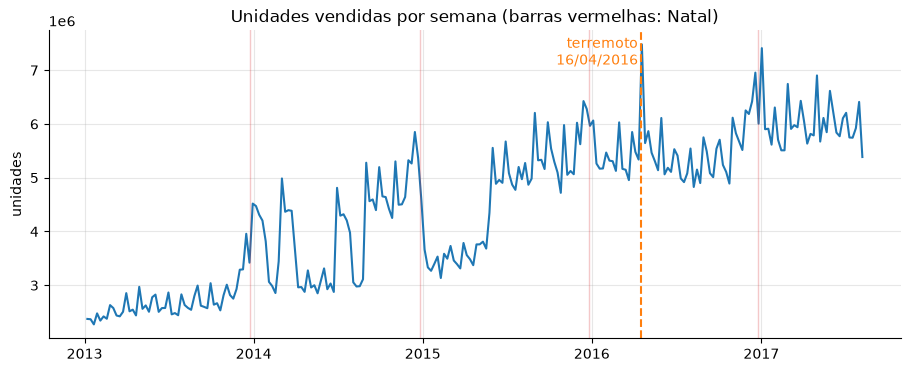

semanas: 240 | 2013-01-07 → 2017-08-07


In [5]:
weekly_total = complete.groupby("week_start").sales.sum()

fig, ax = plt.subplots()
ax.plot(weekly_total.index, weekly_total, lw=1.5)
for year in range(2013, 2017):
    ax.axvline(pd.Timestamp(f"{year}-12-25"), color="tab:red", alpha=0.25, lw=1)
ax.axvline(pd.Timestamp("2016-04-16"), color="tab:orange", lw=1.5, ls="--")
ax.annotate("terremoto\n16/04/2016", (pd.Timestamp("2016-04-10"), weekly_total.max() * 0.95),
            ha="right", color="tab:orange")
ax.set_title("Unidades vendidas por semana (barras vermelhas: Natal)")
ax.set_ylabel("unidades")
plt.show()

print("semanas:", len(weekly_total), "|", weekly_total.index.min().date(), "→", weekly_total.index.max().date())

## 4. Padrão por dia da semana e por mês

Índice = média daquele dia/mês ÷ média geral (1,00 = média).

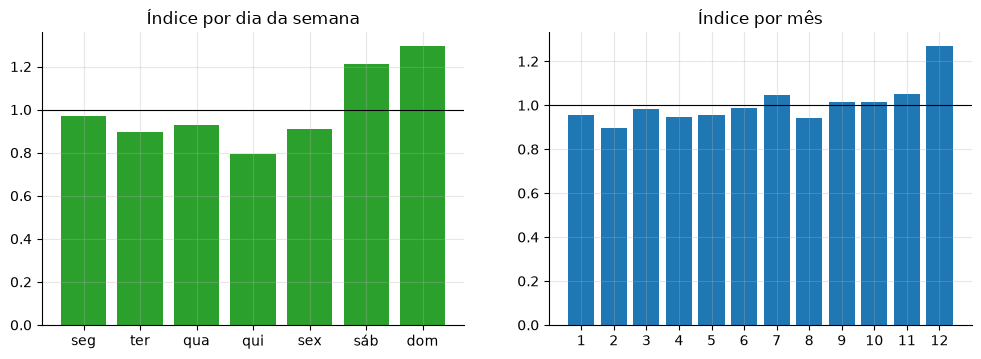

dia,seg,ter,qua,qui,sex,sáb,dom
índice,0.97,0.89,0.93,0.79,0.91,1.21,1.29


In [6]:
names = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
weekday_idx = total_daily.groupby(total_daily.index.dayofweek).mean() / total_daily.mean()
month_idx = total_daily.groupby(total_daily.index.month).mean() / total_daily.mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(names, weekday_idx.values, color="tab:green")
axes[0].set_title("Índice por dia da semana")
axes[1].bar(range(1, 13), month_idx.values, color="tab:blue")
axes[1].set_xticks(range(1, 13))
axes[1].set_title("Índice por mês")
for ax in axes:
    ax.axhline(1, color="k", lw=0.8)
plt.show()

pd.DataFrame({"dia": names, "índice": weekday_idx.values.round(3)}).set_index("dia").T

**Leitura.** O fim de semana vende bem mais que o meio da semana (sábado e domingo ≈ 1,2–1,3× a média; quinta é o dia mais fraco, ≈ 0,8×).
A agregação semanal (Etapa 2) tira esse ruído, mas também apaga o perfil dentro da semana, que a Fase 3 recupera.
Em dezembro o índice mensal passa de 1,25. O índice mensal mistura tendência (2013 é menor que 2016) com sazonalidade, então vale como
indício e não como medida limpa; a Fase 2 trata isso com *features* de calendário.

## 5. Quem vende o quê: famílias e lojas

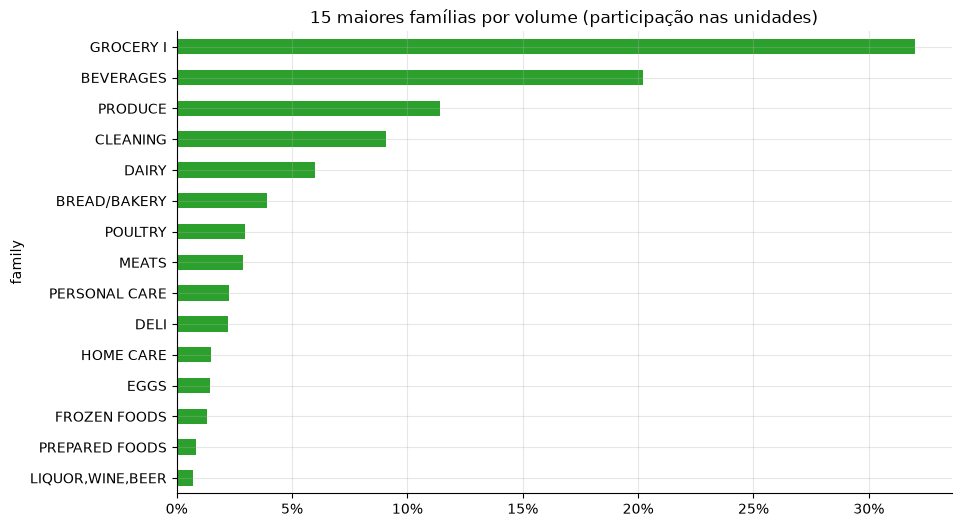

Top 5 somam 78.7%; as 10 menores somam 0.23%.


,participação
family,
MAGAZINES,0.00
HARDWARE,0.00
HOME APPLIANCES,0.00
BABY CARE,0.00
BOOKS,0.00


In [7]:
by_family = daily.groupby("family", observed=True).sales.sum().sort_values(ascending=False)
family_share = (by_family / by_family.sum()).rename("participação")

fig, ax = plt.subplots(figsize=(10, 6))
family_share.head(15)[::-1].plot.barh(ax=ax, color="tab:green")
ax.set_title("15 maiores famílias por volume (participação nas unidades)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.show()

print(f"Top 5 somam {family_share.head(5).sum():.1%}; as 10 menores somam {family_share.tail(10).sum():.2%}.")
family_share.tail(5).to_frame()

In [8]:
by_store = (
    daily.groupby("store_nbr").sales.sum().rename("unidades")
    .to_frame()
    .join(stores.set_index("store_nbr"))
    .sort_values("unidades", ascending=False)
)
display(by_store.head(8))
display(by_store.tail(5))

type_summary = (
    by_store.groupby("type").agg(lojas=("unidades", "size"), media_por_loja=("unidades", "mean"))
    .sort_values("media_por_loja", ascending=False)
)
type_summary

,unidades,city,state,type,cluster
store_nbr,,,,,
44,"62,087,553.25",Quito,Pichincha,A,5
45,"54,498,010.42",Quito,Pichincha,A,11
47,"50,948,310.06",Quito,Pichincha,A,14
3,"50,481,910.19",Quito,Pichincha,D,8
49,"43,420,095.78",Quito,Pichincha,A,11
46,"41,896,062.12",Quito,Pichincha,A,14
48,"35,933,130.27",Quito,Pichincha,A,14
51,"32,911,489.54",Guayaquil,Guayas,A,17


,unidades,city,state,type,cluster
store_nbr,,,,,
35,"7,676,679.42",Playas,Guayas,C,3
30,"7,382,073.66",Guayaquil,Guayas,C,3
32,"5,951,796.00",Guayaquil,Guayas,C,3
22,"4,090,201.74",Puyo,Pastaza,C,7
52,"2,696,169.73",Manta,Manabi,A,11


,lojas,media_por_loja
type,,
A,9,"39,227,093.53"
D,18,"19,504,627.60"
B,8,"18,157,579.39"
E,4,"14,955,608.96"
C,15,"10,962,316.17"


**Leitura.** O volume é muito concentrado: GROCERY I e BEVERAGES respondem por mais da metade das unidades, e há famílias praticamente
sem venda (BOOKS, BABY CARE). Por loja, as de **tipo A** (Quito) lideram com folga; as de tipo C, pequenas, estão no fim. A loja 44 é a
maior; a 52 (Manta) é a menor, mas ela abriu tarde (seção 6). Isso importa para o recorte da Etapa 3: volume e tipo de loja precisam variar.

## 6. Quando cada série "nasce"

Data da **primeira venda positiva** de cada par loja × família. Muitos zeros do início são séries que ainda não existiam.

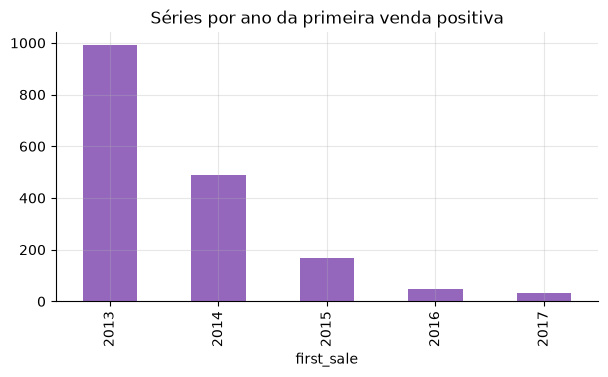

Séries que nunca venderam: 53
Séries cuja primeira venda é depois de 2013: 736 de 1782


,séries
family,
CELEBRATION,54
PET SUPPLIES,54
HOME AND KITCHEN I,54
HOME AND KITCHEN II,54
SCHOOL AND OFFICE SUPPLIES,54
MAGAZINES,54
PLAYERS AND ELECTRONICS,54
HOME CARE,54


In [9]:
first_sale = (
    daily[daily.sales > 0]
    .groupby(["store_nbr", "family"], observed=True).date.min()
    .rename("first_sale").reset_index()
)
never_sold = len(series_sizes) - len(first_sale)

by_year = first_sale.first_sale.dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.5))
by_year.plot.bar(ax=ax, color="tab:purple")
ax.set_title("Séries por ano da primeira venda positiva")
plt.show()

after_2013 = first_sale[first_sale.first_sale > "2013-12-31"]
print(f"Séries que nunca venderam: {never_sold}")
print(f"Séries cuja primeira venda é depois de 2013: {len(after_2013)} de {len(series_sizes)}")
after_2013.groupby("family", observed=True).size().sort_values(ascending=False).head(8).to_frame("séries")

**Leitura.** Só 993 das 1.782 séries vendem já em 2013; 736 começam depois e 53 nunca vendem nada. Várias famílias (CELEBRATION, PET SUPPLIES,
HOME AND KITCHEN, SCHOOL AND OFFICE SUPPLIES, MAGAZINES…) só passam a ser registradas em **todas** as 54 lojas depois de 2013. Para a Fase 1 isso
significa: **só séries com histórico completo** servem, o que é a razão do critério 1 da Etapa 3.

## 7. Eventos anômalos

### 7.1 Terremoto de Manabí (16/04/2016)

,date,type,locale_name,description
219,2016-04-16,Event,Ecuador,Terremoto Manabi
220,2016-04-17,Event,Ecuador,Terremoto Manabi+1
221,2016-04-18,Event,Ecuador,Terremoto Manabi+2
222,2016-04-19,Event,Ecuador,Terremoto Manabi+3
223,2016-04-20,Event,Ecuador,Terremoto Manabi+4
225,2016-04-21,Event,Ecuador,Terremoto Manabi+5
226,2016-04-22,Event,Ecuador,Terremoto Manabi+6
227,2016-04-23,Event,Ecuador,Terremoto Manabi+7


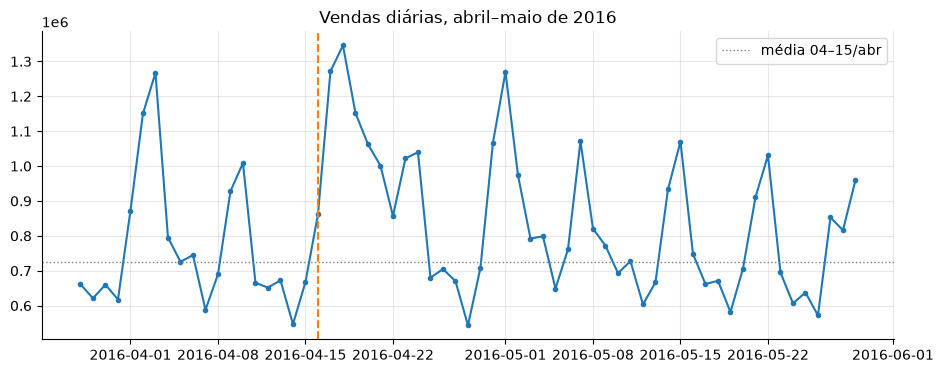

Média 04–15/abr: 723,692 | média 17–19/abr: 1,256,615


In [10]:
quake = holidays[holidays.description.str.contains("Terremoto", case=False)]
display(quake[["date", "type", "locale_name", "description"]].head(8))

window = total_daily["2016-03-28":"2016-05-29"]
base = total_daily["2016-04-04":"2016-04-15"].mean()

fig, ax = plt.subplots()
ax.plot(window.index, window, marker="o", ms=3)
ax.axvline(pd.Timestamp("2016-04-16"), color="tab:orange", ls="--")
ax.axhline(base, color="grey", lw=1, ls=":", label="média 04–15/abr")
ax.set_title("Vendas diárias, abril–maio de 2016")
ax.legend()
plt.show()

print(f"Média 04–15/abr: {base:,.0f} | média 17–19/abr: {total_daily['2016-04-17':'2016-04-19'].mean():,.0f}")

**Leitura.** Depois do terremoto a venda **sobe**, não cai: nos três dias seguintes a média é bem maior que a da quinzena anterior
(compra de emergência e doações). É um *outlier* de demanda genuíno, e não falha de registro. Um modelo sem uma marca desse evento vai tratá-lo
como ruído ou aprender errado. O arquivo `holidays_events.csv` marca o evento (e seus dias seguintes, `Terremoto Manabi+1`, `+2`…), o que permite virar *feature* na Fase 2.

### 7.2 Viradas de ano

,24/12,25/12,26/12,31/12,01/01
ano,,,,,
2013,"620,663.29",None,"470,731.16","507,264.66","8,602.07"
2014,"965,982.87",None,"872,098.46","844,380.47","12,773.62"
2015,"1,083,680.32",None,"946,725.19","964,641.54","16,433.39"
2016,"1,246,837.84",None,"1,032,770.75","1,109,012.81","12,082.50"


Média diária geral: 637,556
1º de janeiro de 2013: 2,512


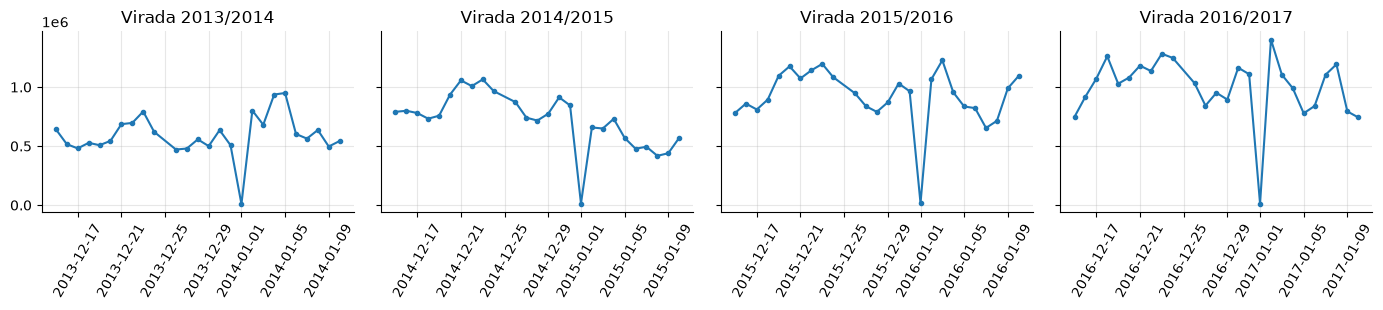

In [11]:
rows = []
for y in (2013, 2014, 2015, 2016):
    rows.append({
        "ano": y,
        "24/12": total_daily.get(pd.Timestamp(f"{y}-12-24")),
        "25/12": total_daily.get(pd.Timestamp(f"{y}-12-25")),  # ausente
        "26/12": total_daily.get(pd.Timestamp(f"{y}-12-26")),
        "31/12": total_daily.get(pd.Timestamp(f"{y}-12-31")),
        "01/01": total_daily.get(pd.Timestamp(f"{y+1}-01-01")),
    })
newyear = pd.DataFrame(rows).set_index("ano")
display(newyear)
print(f"Média diária geral: {total_daily.mean():,.0f}")
print("1º de janeiro de 2013:", f"{total_daily.get(pd.Timestamp('2013-01-01')):,.0f}")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, y in zip(axes, (2013, 2014, 2015, 2016)):
    seg = total_daily[f"{y}-12-15":f"{y+1}-01-10"]
    ax.plot(seg.index, seg, marker="o", ms=3)
    ax.set_title(f"Virada {y}/{y+1}")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

**Leitura.** Em 25/12 não há linha (loja fechada). Em **1º de janeiro** quase nada é vendido (dezenas de vezes menos
que um dia normal), e 24/12 fica bem acima da média diária do ano. Como a semana do Natal só tem 6 dias com registro, a soma semanal dessa semana cai
artificialmente; isso é o que a coluna `n_days` da Etapa 2 vai sinalizar. Espera-se que os maiores erros do baseline apareçam justamente aqui.

## 8. Conclusões da exploração

| Componente | O que se viu |
|---|---|
| **Tendência** | Alta de 2013 a 2016, em parte por entrada de novas lojas/famílias; não é só demanda |
| **Sazonalidade semanal** | Sábado e domingo ≈ 1,2–1,3× a média; quinta ≈ 0,8× |
| **Sazonalidade anual** | Pico em dezembro (≈ 1,25×) |
| **Eventos** | Terremoto (venda sobe por poucos dias), fechamento em 25/12 e quase nada em 1º/01 |
| **Zeros** | 31% das linhas; boa parte é série inexistente, não demanda zero |
| **Concentração** | Poucas famílias e lojas dominam o volume |

**Implicações para as próximas etapas**

1. **Etapa 2 (semana):** semanas completas seg–dom, rótulo na segunda, `n_days` para sinalizar a semana de Natal.
2. **Etapa 3 (recorte):** exigir histórico completo e nenhuma semana zerada; variar volume e tipo de loja; evitar PRODUCE.
3. **Etapa 5 (baseline):** a média móvel vai falhar em tendência, feriados e eventos — é aí que a Fase 2 deve ganhar.